In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from datasets import load_dataset

In [2]:
emotion_dataset =load_dataset('dair-ai/emotion')
train_text      =emotion_dataset['train']['text']
train_label     =emotion_dataset['train']['label']

test_text       =emotion_dataset['test']['text']
test_label      =emotion_dataset['test']['label']

README.md:   0%|          | 0.00/9.05k [00:00<?, ?B/s]

split/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 1.03MB            

split/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

split/validation-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  127kB            

split/validation-00000-of-00001.parquet: downloading bytes:           |  0.00B            

split/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  129kB            

split/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/16000 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/2000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/2000 [00:00<?, ? examples/s]

In [3]:
label_names=emotion_dataset['train'].features['label'].names

In [4]:
df_train = pd.DataFrame(
    {
        'text': train_text,
        'label':[label_names[i] for i in train_label]
    }
)

In [5]:
df_test = pd.DataFrame(
    {
        'text':test_text,
        'label':[label_names[i] for i in test_label]
    }
)

In [6]:
df_test.sample(5)


,text,label
375,im feeling a lot less ugly duckling and a lot ...,sadness
930,i cant remember exactly what made me stop usin...,anger
1257,ill let myself shed a few tears and feel bitte...,anger
1048,i wonder if the homeowners would feel weird if...,surprise
1902,i ever recognized what it was to feel passiona...,love


EDA(Exploratory Data Analysis)

<Axes: xlabel='label', ylabel='count'>

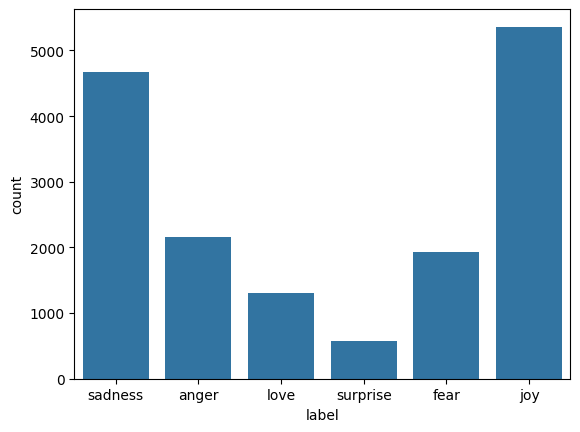

In [7]:
sns.countplot(x='label',data=df_train)

NLP

In [8]:
#Tokenize
max_token = 10000
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

tokenizer=Tokenizer(num_words=max_token,oov_token='<unk>')

In [9]:
tokenizer.fit_on_texts(df_train['text'])
train_sequence =tokenizer.texts_to_sequences(df_train['text'])
test_sequence  =tokenizer.texts_to_sequences(df_test['text'])

In [10]:
##Now we will pad the train sequence because after we need to give that input to DL model which operates at equal input

padded_train_sequence  = pad_sequences(train_sequence,maxlen=50,padding='post',truncating='post')
padded_test_sequence   = pad_sequences(test_sequence,maxlen=50,padding='post',truncating='post')

train_labels = np.array(train_label)
test_labels  = np.array(test_label)

num_classes = len(np.unique(train_labels))

In [11]:
from sklearn.utils import class_weight

class_weights = class_weight.compute_class_weight(
    class_weight = 'balanced',
    classes = np.unique(train_labels),
    y=train_labels

)

class_weights_dic=dict(enumerate(class_weights))


In [12]:
from tensorflow.keras.callbacks import EarlyStopping

early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True
)

In [13]:
# from tensorflow.keras.models import Sequential
# from tensorflow.keras.layers import SimpleRNN,Embedding,Dense,Dropout,LSTM,GRU

# rnn_model = Sequential([
#     Embedding(input_dim = max_token,output_dim = 128, input_length=50),
#     SimpleRNN(units=128,return_sequences=True),
#     Dropout(0.5),
#     SimpleRNN(units=64),
#     Dropout(0.5),
#     Dense(units=num_classes, activation='softmax')
# ]
# )

# rnn_model.compile(
#     optimizer='adam',
#     loss = 'sparse_categorical_crossentropy',
#     metrics=['accuracy']
# )


In [14]:
# rnn_model.fit(
#     padded_train_sequence,
#     train_labels,
#     validation_data=(padded_test_sequence,test_labels),
#     epochs=20,
#     batch_size=32,
#     validation_split=0.2,
#     class_weight=class_weights_dic,
#     callbacks=[early_stopping]
# )
# rnn_loss,rnn_accuracy=rnn_model.evaluate(padded_test_sequence,test_labels)
# print(f"RNN LOSS: {rnn_loss}")
# print(f"RNN Accuracy: {rnn_accuracy}")

In [15]:
# ##LSTM
# lstm_model = Sequential([
#     Embedding(input_dim = max_token,output_dim = 128, input_length=50),
#     LSTM(units=128,return_sequences=True),
#     Dropout(0.5),
#     LSTM(units=64),
#     Dropout(0.5),
#     Dense(units=num_classes, activation='softmax')
# ]
# )

# lstm_model.compile(
#     optimizer='adam',
#     loss = 'sparse_categorical_crossentropy',
#     metrics=['accuracy']
# )
# lstm_model.fit(
#     padded_train_sequence,
#     train_labels,
#     validation_data=(padded_test_sequence,test_labels),
#     epochs=20,
#     batch_size=32,
#     class_weight=class_weights_dic,
#     callbacks=[early_stopping]
# )
# lstm_loss,lstm_accuracy=lstm_model.evaluate(padded_test_sequence,test_labels)
# print(f"LSTM LOSS: {lstm_loss}")
# print(f"LSTM Accuracy: {lstm_accuracy}")

In [16]:
# ##GRU
# gru_model = Sequential([
#     Embedding(input_dim = max_token,output_dim = 128, input_length=50),
#     GRU(units=128,return_sequences=True),
#     Dropout(0.5),
#     GRU(units=64),
#     Dropout(0.5),
#     Dense(units=num_classes, activation='softmax')
# ]
# )

# gru_model.compile(
#     optimizer='adam',
#     loss = 'sparse_categorical_crossentropy',
#     metrics=['accuracy']
# )
# gru_model.fit(
#     padded_train_sequence,
#     train_labels,
#     validation_data=(padded_test_sequence,test_labels),
#     epochs=20,
#     batch_size=32,
#     class_weight=class_weights_dic,
#     callbacks=[early_stopping]
# )
# gru_loss,gru_accuracy=lstm_model.evaluate(padded_test_sequence,test_labels)
# print(f"gru LOSS: {gru_loss}")
# print(f"gru Accuracy: {gru_accuracy}")

In [17]:
# result_df = pd.DataFrame({
#     'Model':['RNN','LSTM','GRU'],
#     'Test Loss':[rnn_loss,lstm_loss,gru_loss],
#     'Test Accuracy':[rnn_accuracy,lstm_accuracy,gru_accuracy]
# }).sort_values(by='Test Accuracy',ascending=False)

In [20]:
#3 BIderectional GRU
from tensorflow.keras.layers import Bidirectional
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, GRU, Bidirectional, Dropout, Dense

BiGRU = Sequential([
     Embedding(input_dim = max_token,output_dim = 300, input_length=50),
     Bidirectional(GRU(128,return_sequences=True)),
     Dropout(0.5),
     Bidirectional(GRU(64)),
     Dropout(0.5),
     Dense(num_classes, activation='softmax')
])

BiGRU.compile(optimizer='adam',loss='sparse_categorical_crossentropy',metrics=['accuracy'])

BiGRU.fit(
    padded_train_sequence,
    train_labels,
    validation_data=(padded_test_sequence,test_labels),
    epochs=20,
    batch_size=32,
    class_weight=class_weights_dic,
    callbacks=[early_stopping]
)


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Epoch 1/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 147s 268ms/step - accuracy: 0.5846 - loss: 1.0148 - val_accuracy: 0.8905 - val_loss: 0.3642
Epoch 2/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 137s 259ms/step - accuracy: 0.9190 - loss: 0.2218 - val_accuracy: 0.9190 - val_loss: 0.2091
Epoch 3/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 131s 261ms/step - accuracy: 0.9458 - loss: 0.1503 - val_accuracy: 0.9160 - val_loss: 0.2280
Epoch 4/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 131s 262ms/step - accuracy: 0.9587 - loss: 0.1133 - val_accuracy: 0.9260 - val_loss: 0.2154
Epoch 5/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 129s 258ms/step - accuracy: 0.9702 - loss: 0.0787 - val_accuracy: 0.9195 - val_loss: 0.2490


In [21]:
Bigru_loss,Bigru_accuracy=BiGRU.evaluate(padded_test_sequence,test_labels)
print(f"Bigru LOSS: {Bigru_loss}")
print(f"Bigru Accuracy: {Bigru_accuracy}")

63/63 ━━━━━━━━━━━━━━━━━━━━ 5s 75ms/step - accuracy: 0.9190 - loss: 0.2091
Bigru LOSS: 0.20908719301223755
Bigru Accuracy: 0.9190000295639038


63/63 ━━━━━━━━━━━━━━━━━━━━ 4s 63ms/step


<Axes: >

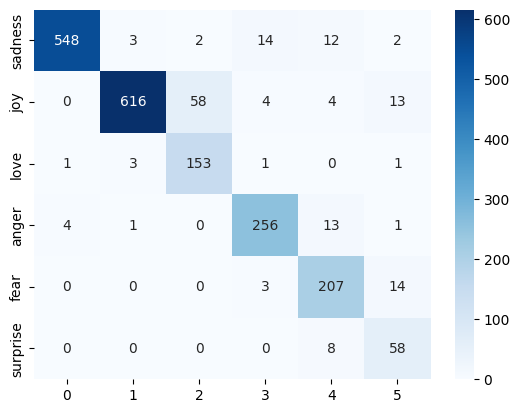

In [22]:
## Confusion Matrix
label_names=emotion_dataset['train'].features['label'].names

from sklearn.metrics import confusion_matrix

BiGRU_predictions=np.argmax(BiGRU.predict(padded_test_sequence),axis=1)

sns.heatmap(confusion_matrix(test_label,BiGRU_predictions),annot=True,fmt='d',cmap='Blues',yticklabels=label_names)


In [23]:
#Final Predictions
sample_text = [
"I absolutely love this new smartphone! The camera quality is outstanding, and the battery easily lasts for two full days. Highly recommended.",
"Horrible customer service. The application kept crashing every time I tried to log in, and the support team completely ignored my emails.",
"The package arrived on Tuesday as expected. The build quality of the table is okay, nothing special, but it serves its purpose for the price."
]

sample_sequences = tokenizer.texts_to_sequences(sample_text)
sample_padded_sequences = pad_sequences(sample_sequences,maxlen=50,padding='post',truncating='post')

sample_predictions = np.argmax(BiGRU.predict(sample_padded_sequences),axis=1)
for i in range(len(sample_text)):
  print(f'Text : {sample_text[i]}\n Predicted Emotion:{label_names[sample_predictions[i]]}')

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step
Text : I absolutely love this new smartphone! The camera quality is outstanding, and the battery easily lasts for two full days. Highly recommended.
 Predicted Emotion:joy
Text : Horrible customer service. The application kept crashing every time I tried to log in, and the support team completely ignored my emails.
 Predicted Emotion:sadness
Text : The package arrived on Tuesday as expected. The build quality of the table is okay, nothing special, but it serves its purpose for the price.
 Predicted Emotion:joy


SAVE MODEL

In [25]:
import os
import pickle

model_dir='Artifacts'
os.makedirs(model_dir,exist_ok=True) #folder jismein ssari exported files ayegi

BiGRU.save(os.path.join(model_dir,'BiGRU_Model.keras'))

with open(os.path.join(model_dir,'tokenizer.pkl'),'wb') as file:
  pickle.dump(tokenizer,file)

